In [ ]:
import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("PyTorch CUDA:", torch.version.cuda)
print("cuDNN:", torch.backends.cudnn.version())
print("GPU 可用:", torch.cuda.is_available())

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        gpu = torch.cuda.get_device_properties(i)
        print(f"GPU {i}: {gpu.name}")
        print(f"总显存: {gpu.total_memory / 1024**3:.1f} GiB")

!nvidia-smi
!pip show torchvision pytorch-ignite kagglehub
!df -h /content

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
PyTorch CUDA: 13.0
cuDNN: 92700
GPU 可用: True
GPU 0: NVIDIA L4
总显存: 22.0 GiB
Sun Oct 25 18:53:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   40C    P8             14W /   72W |       3MiB /  23034MiB |      0

In [ ]:
import sys
from pathlib import Path
import torch
import kagglehub

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("PyTorch CUDA:", torch.version.cuda)

if torch.cuda.is_available():
    gpu = torch.cuda.get_device_properties(0)
    print("GPU:", gpu.name)
    print(f"显存: {gpu.total_memory / 1024**3:.1f} GiB")

dataset_path = Path(
    kagglehub.dataset_download(
        "paultimothymooney/chest-xray-pneumonia"
    )
)
print("\n数据下载位置:", dataset_path)
candidates = [dataset_path] + [
    p for p in dataset_path.rglob("*") if p.is_dir()
]
roots = [
    p for p in candidates
    if all((p / split).is_dir() for split in ("train", "val", "test"))
]

for root in roots:
    print("\n数据根目录:", root)
    for split in ("train", "val", "test"):
        for label in ("NORMAL", "PNEUMONIA"):
            folder = root / split / label
            count = sum(
                p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
                for p in folder.rglob("*")
            )
            print(f"{split}/{label}: {count} 张")

if not roots:
    print("未找到标准目录结构，请把输出发给我检查。")

Python: 3.13.16
PyTorch: 2.11.0+cu130
PyTorch CUDA: 13.0
GPU: NVIDIA L4
显存: 22.0 GiB
Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.

数据下载位置: /kaggle/input/chest-xray-pneumonia

数据根目录: /kaggle/input/chest-xray-pneumonia/chest_xray
train/NORMAL: 1341 张
train/PNEUMONIA: 3875 张
val/NORMAL: 8 张
val/PNEUMONIA: 8 张
test/NORMAL: 234 张
test/PNEUMONIA: 390 张

数据根目录: /kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray
train/NORMAL: 1341 张
train/PNEUMONIA: 3875 张
val/NORMAL: 8 张
val/PNEUMONIA: 8 张
test/NORMAL: 234 张
test/PNEUMONIA: 390 张

数据根目录: /kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray
train/NORMAL: 1341 张
train/PNEUMONIA: 3875 张
val/NORMAL: 8 张
val/PNEUMONIA: 8 张
test/NORMAL: 234 张
test/PNEUMONIA: 390 张


In [3]:
from pathlib import Path

DATA_ROOT = Path("/kaggle/input/chest-xray-pneumonia/chest_xray")

print("运行环境已连接", flush=True)
for split in ("train", "val", "test"):
    folder = DATA_ROOT / split
    print(f"{split}: 存在={folder.is_dir()}", flush=True)

运行环境已连接
train: 存在=True
val: 存在=True
test: 存在=True


train/NORMAL: 1341 张
train/PNEUMONIA: 3875 张
NORMAL2-IM-1337-0001.jpeg: size=(1360, 1097), mode=L
IM-0431-0001.jpeg: size=(1678, 1414), mode=L
person1060_virus_1760.jpeg: size=(1312, 920), mode=L
person583_bacteria_2408.jpeg: size=(1360, 1080), mode=L


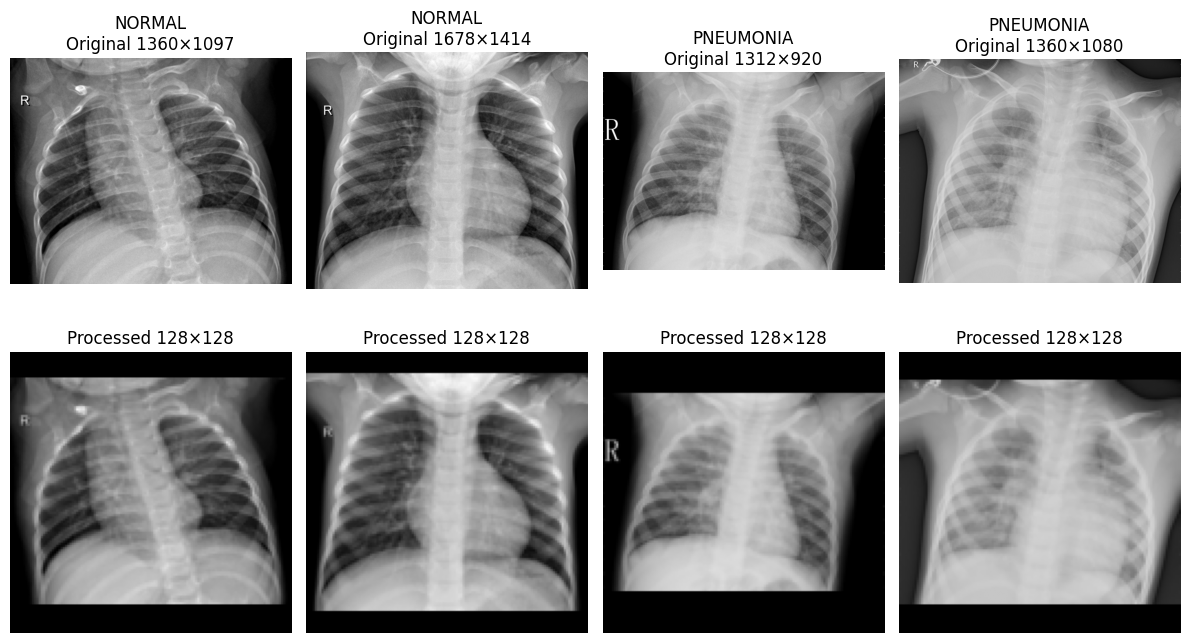

In [ ]:
from pathlib import Path
import random
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

DATA_ROOT = Path("/kaggle/input/chest-xray-pneumonia/chest_xray")
rng = random.Random(42)

samples = []
for label in ("NORMAL", "PNEUMONIA"):
    files = sorted(
        p for p in (DATA_ROOT / "train" / label).iterdir()
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )
    print(f"train/{label}: {len(files)} 张")
    samples.extend((label, p) for p in rng.sample(files, 2))

fig, axes = plt.subplots(2, 4, figsize=(12, 7))

for col, (label, path) in enumerate(samples):
    with Image.open(path) as source:
        original_mode = source.mode
        image = source.convert("L")
    processed = ImageOps.pad(
        image,
        size=(128, 128),
        method=Image.Resampling.BILINEAR,
        color=0,
        centering=(0.5, 0.5),
    )

    print(f"{path.name}: size={image.size}, mode={original_mode}")

    axes[0, col].imshow(image, cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(f"{label}\nOriginal {image.width}×{image.height}")

    axes[1, col].imshow(processed, cmap="gray", vmin=0, vmax=255)
    axes[1, col].set_title("Processed 128×128")

    axes[0, col].axis("off")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
from collections import defaultdict
import random
import re
import json

DATA_ROOT = Path("/kaggle/input/chest-xray-pneumonia/chest_xray")
OUTPUT_DIR = Path("/content/vae_experiment")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
VAL_RATIO = 0.10
LABELS = ("NORMAL", "PNEUMONIA")
EXTENSIONS = {".jpg", ".jpeg", ".png"}

def filename_group(path, label):
    match = re.match(
        r"^(NORMAL2-IM-\d+|IM-\d+|person\d+)(?:[-_]|$)",
        path.stem,
    )
    if match is None:
        raise ValueError(f"未识别的文件名，请把此错误发给我：{path.name}")
    return f"{label}/{match.group(1)}"

def collect_records(split):
    records = []
    for label in LABELS:
        folder = DATA_ROOT / split / label
        assert folder.is_dir(), f"目录不存在：{folder}"

        for path in sorted(folder.iterdir()):
            if path.is_file() and path.suffix.lower() in EXTENSIONS:
                records.append({
                    "path": str(path),
                    "label": label,
                    "group": filename_group(path, label),
                    "original_split": split,
                })
    return records

development_records = collect_records("train") + collect_records("val")
test_records = collect_records("test")

train_records, val_records = [], []
rng = random.Random(SEED)

for label in LABELS:
    groups = defaultdict(list)
    for record in development_records:
        if record["label"] == label:
            groups[record["group"]].append(record)

    group_ids = sorted(groups)
    rng.shuffle(group_ids)
    assert len(group_ids) >= 2, f"{label} 的分组数量不足"

    n_val = min(
        len(group_ids) - 1,
        max(1, round(len(group_ids) * VAL_RATIO)),
    )
    val_group_ids = set(group_ids[:n_val])

    for group_id in group_ids:
        destination = val_records if group_id in val_group_ids else train_records
        destination.extend(groups[group_id])

assert not (
    {r["group"] for r in train_records}
    & {r["group"] for r in val_records}
), "训练集与验证集存在分组交叉"

manifest = {
    "seed": SEED,
    "validation_group_fraction": VAL_RATIO,
    "train": train_records,
    "val": val_records,
    "test": test_records,
}

manifest_path = OUTPUT_DIR / "data_split.json"
manifest_path.write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

for split in ("train", "val", "test"):
    records = manifest[split]
    counts = {
        label: sum(r["label"] == label for r in records)
        for label in LABELS
    }
    print(f"{split}: {len(records)} 张 | {counts}")

print(f"\n划分已保存：{manifest_path}")

train: 4682 张 | {'NORMAL': 1209, 'PNEUMONIA': 3473}
val: 550 张 | {'NORMAL': 140, 'PNEUMONIA': 410}
test: 624 张 | {'NORMAL': 234, 'PNEUMONIA': 390}

划分已保存：/content/vae_experiment/data_split.json


In [ ]:
import json
from pathlib import Path
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageOps
from torchvision.transforms.functional import to_tensor

manifest = json.loads(
    Path("/content/vae_experiment/data_split.json").read_text(
        encoding="utf-8"
    )
)

class ChestXrayDataset(Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        path = self.records[index]["path"]

        with Image.open(path) as source:
            image = source.convert("L")
            image = ImageOps.pad(
                image,
                size=(128, 128),
                method=Image.Resampling.BILINEAR,
                color=0,
                centering=(0.5, 0.5),
            )
        return to_tensor(image)

train_dataset = ChestXrayDataset(manifest["train"])
val_dataset = ChestXrayDataset(manifest["val"])
test_dataset = ChestXrayDataset(manifest["test"])

loader_options = {
    "batch_size": 32,
    "num_workers": 2,
    "pin_memory": torch.cuda.is_available(),
    "drop_last": False,
}

train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    generator=torch.Generator().manual_seed(manifest["seed"]),
    **loader_options,
)
val_loader = DataLoader(
    val_dataset, shuffle=False, **loader_options
)
test_loader = DataLoader(
    test_dataset, shuffle=False, **loader_options
)

batch = next(iter(train_loader))

assert batch.shape == (32, 1, 128, 128)
assert batch.dtype == torch.float32
assert torch.isfinite(batch).all()
assert batch.min() >= 0 and batch.max() <= 1

print("Batch shape:", tuple(batch.shape))
print("数据类型:", batch.dtype)
print("像素范围:", batch.min().item(), "到", batch.max().item())
print("训练 / 验证 / 测试 batch 数:",
      len(train_loader), len(val_loader), len(test_loader))
print("DataLoader 检查通过")

Batch shape: (32, 1, 128, 128)
数据类型: torch.float32
像素范围: 0.0 到 1.0
训练 / 验证 / 测试 batch 数: 147 18 20
DataLoader 检查通过


In [ ]:
import torch
from torch import nn

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.SiLU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.SiLU(),
        )

    def forward(self, x):
        return self.block(x)


class VAE(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.latent_dim = latent_dim

        encoder = []
        in_channels = 1
        for out_channels in (32, 64, 128, 256, 256):
            encoder.extend([
                DoubleConv(in_channels, out_channels),
                nn.AvgPool2d(2),
            ])
            in_channels = out_channels
        self.encoder = nn.Sequential(*encoder)

        self.fc_mu = nn.Linear(256 * 4 * 4, latent_dim)
        self.fc_logvar = nn.Linear(256 * 4 * 4, latent_dim)
        self.fc_decode = nn.Linear(latent_dim, 256 * 4 * 4)

        decoder = []
        in_channels = 256
        for out_channels in (256, 128, 64, 32, 32):
            decoder.extend([
                nn.Upsample(scale_factor=2, mode="nearest"),
                DoubleConv(in_channels, out_channels),
            ])
            in_channels = out_channels
        self.decoder = nn.Sequential(*decoder)

        self.output = nn.Sequential(
            nn.Conv2d(32, 1, kernel_size=3, padding=1),
            nn.Sigmoid(),
        )

    def encode(self, x):
        features = self.encoder(x).flatten(start_dim=1)
        return self.fc_mu(features), self.fc_logvar(features)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + std * torch.randn_like(std)

    def decode(self, z):
        features = self.fc_decode(z).reshape(-1, 256, 4, 4)
        return self.output(self.decoder(features))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = VAE(latent_dim=128).to(device)
model.eval()

with torch.no_grad():
    x = batch[:2].to(device)
    reconstruction, mu, logvar = model(x)
    generated = model.decode(torch.randn(2, 128, device=device))

assert reconstruction.shape == x.shape
assert mu.shape == logvar.shape == (2, 128)
assert generated.shape == (2, 1, 128, 128)
assert all(
    torch.isfinite(t).all().item()
    for t in (reconstruction, mu, logvar, generated)
)
model.train()

print("设备:", device)
print("参数量:", f"{sum(p.numel() for p in model.parameters()):,}")
print("重建尺寸:", tuple(reconstruction.shape))
print("μ / log σ² 尺寸:", tuple(mu.shape))
print("随机生成尺寸:", tuple(generated.shape))
print("模型前向检查通过")

设备: cuda
参数量: 5,711,553
重建尺寸: (2, 1, 128, 128)
μ / log σ² 尺寸: (2, 128)
随机生成尺寸: (2, 1, 128, 128)
模型前向检查通过


In [ ]:
def vae_loss(reconstruction, target, mu, logvar):
    reconstruction_loss = (
        (reconstruction - target).square()
        .flatten(start_dim=1)
        .sum(dim=1)
        .mean()
    )

    kl_loss = -0.5 * (
        1 + logvar - mu.square() - logvar.exp()
    ).sum(dim=1).mean()

    total_loss = reconstruction_loss + kl_loss
    return total_loss, reconstruction_loss, kl_loss

saved_buffers = {
    name: buffer.detach().clone()
    for name, buffer in model.named_buffers()
}
previous_training = model.training

try:
    model.train()
    model.zero_grad(set_to_none=True)
    with torch.random.fork_rng(devices=[torch.cuda.current_device()]):
        x_check = batch.to(device)
        recon_check, mu_check, logvar_check = model(x_check)

        total, reconstruction_loss, kl_loss = vae_loss(
            recon_check, x_check, mu_check, logvar_check
        )
        assert torch.isfinite(total).item(), "损失出现 NaN 或 Inf"

        total.backward()

        missing_gradients = []
        invalid_gradients = []

        for name, parameter in model.named_parameters():
            if parameter.requires_grad:
                if parameter.grad is None:
                    missing_gradients.append(name)
                elif not torch.isfinite(parameter.grad).all().item():
                    invalid_gradients.append(name)

        assert not missing_gradients, f"缺少梯度: {missing_gradients}"
        assert not invalid_gradients, f"梯度异常: {invalid_gradients}"

        print(f"总损失: {total.item():.4f}")
        print(f"重建损失: {reconstruction_loss.item():.4f}")
        print(f"KL 散度: {kl_loss.item():.4f}")
        print("完整 batch（32 张）反向传播检查通过，未更新参数")

finally:
    model.zero_grad(set_to_none=True)
    with torch.no_grad():
        for name, buffer in model.named_buffers():
            buffer.copy_(saved_buffers[name])
    model.train(previous_training)

总损失: 1814.6958
重建损失: 1808.0029
KL 散度: 6.6928
完整 batch（32 张）反向传播检查通过，未更新参数


In [9]:
from google.colab import drive
from pathlib import Path
from datetime import datetime, timezone
import json
import shutil

drive.mount("/content/drive")

run_name = datetime.now(timezone.utc).strftime("vae_%Y%m%d_%H%M%S_UTC")
RUN_DIR = Path("/content/drive/MyDrive/ECE285_HW1") / run_name
RUN_DIR.mkdir(parents=True, exist_ok=False)

config = {
    "seed": 42,
    "image_size": 128,
    "image_channels": 1,
    "latent_dim": 128,
    "batch_size": 32,
    "normalization": "BatchNorm2d",
    "downsampling": "AvgPool2d",
    "upsampling": "nearest",
    "residual_connections": False,
    "optimizer": "Adam",
    "learning_rate": 2e-4,
    "epochs": 100,
    "kl_weight": 1.0,
    "reconstruction_loss": "pixel squared error summed per image",
    "loss_reduction": "mean over batch",
    "preprocessing": "aspect-ratio-preserving resize and black padding",
    "torch_version": str(torch.__version__),
}

(RUN_DIR / "config.json").write_text(
    json.dumps(config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

shutil.copy2(
    "/content/vae_experiment/data_split.json",
    RUN_DIR / "data_split.json",
)

print("实验保存目录:", RUN_DIR)
print("配置与数据划分已备份")

Mounted at /content/drive
实验保存目录: /content/drive/MyDrive/ECE285_HW1/vae_20261025_192111_UTC
配置与数据划分已备份


In [ ]:
import torch

def vae_loss(reconstruction, target, mu, logvar):
    reconstruction_loss = (
        (reconstruction - target).square()
        .flatten(start_dim=1)
        .sum(dim=1)
        .mean()
    )

    kl_loss = -0.5 * (
        1 + logvar - mu.square() - logvar.exp()
    ).sum(dim=1).mean()

    total_loss = reconstruction_loss + kl_loss
    return total_loss, reconstruction_loss, kl_loss


def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    totals = {
        "loss": 0.0,
        "reconstruction": 0.0,
        "kl": 0.0,
    }
    sample_count = 0

    with torch.set_grad_enabled(training):
        for images in loader:
            images = images.to(device, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            reconstruction, mu, logvar = model(images)
            loss, reconstruction_loss, kl_loss = vae_loss(
                reconstruction, images, mu, logvar
            )

            if not torch.isfinite(loss).item():
                raise RuntimeError("发现非有限损失，停止运行以便排查。")

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=float("inf"),
                    error_if_nonfinite=True,
                )
                optimizer.step()

            batch_size = images.size(0)
            sample_count += batch_size
            totals["loss"] += loss.detach().item() * batch_size
            totals["reconstruction"] += (
                reconstruction_loss.detach().item() * batch_size
            )
            totals["kl"] += kl_loss.detach().item() * batch_size

    if sample_count == 0:
        raise RuntimeError("DataLoader 没有提供任何图片。")

    return {
        name: value / sample_count
        for name, value in totals.items()
    }
print("损失函数和训练 / 验证函数已定义，尚未启动训练")

损失函数和训练 / 验证函数已定义，尚未启动训练


In [ ]:
import json
import random
import time
import torch
from torchvision.utils import save_image

random.seed(config["seed"])
torch.manual_seed(config["seed"])
torch.cuda.manual_seed_all(config["seed"])
train_loader.generator.manual_seed(config["seed"])

model = VAE(latent_dim=config["latent_dim"]).to(device)
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=config["learning_rate"],
)

noise_generator = torch.Generator().manual_seed(2026)
fixed_z = torch.randn(
    16, config["latent_dim"], generator=noise_generator
).to(device)
torch.save(fixed_z.cpu(), RUN_DIR / "fixed_z.pt")

history = []
best_val_loss = float("inf")

def save_checkpoint(filename, checkpoint):
    destination = RUN_DIR / filename
    temporary = RUN_DIR / (filename + ".tmp")
    torch.save(checkpoint, temporary)
    temporary.replace(destination)

print("开始训练，保存位置:", RUN_DIR, flush=True)

for epoch in range(1, config["epochs"] + 1):
    start = time.perf_counter()
    print(f"\nEpoch {epoch}/{config['epochs']} 开始", flush=True)

    train_metrics = run_epoch(model, train_loader, optimizer)
    val_metrics = run_epoch(model, val_loader)
    improved = val_metrics["loss"] < best_val_loss
    if improved:
        best_val_loss = val_metrics["loss"]

    history.append({
        "epoch": epoch,
        "train": train_metrics,
        "val": val_metrics,
        "seconds": time.perf_counter() - start,
    })

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_val_loss": best_val_loss,
        "history": history,
        "config": config,
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_states": torch.cuda.get_rng_state_all(),
        "loader_rng_state": train_loader.generator.get_state(),
    }
    save_checkpoint("last.pt", checkpoint)
    if improved:
        save_checkpoint("best.pt", checkpoint)

    history_tmp = RUN_DIR / "history.json.tmp"
    history_tmp.write_text(
        json.dumps(history, indent=2), encoding="utf-8"
    )
    history_tmp.replace(RUN_DIR / "history.json")

    if epoch == 1 or epoch % 5 == 0:
        model.eval()
        with torch.no_grad():
            generated = model.decode(fixed_z).cpu()
        save_image(
            generated,
            RUN_DIR / f"generated_epoch_{epoch:03d}.png",
            nrow=4,
            normalize=False,
        )

    marker = " | 已更新最佳模型" if improved else ""
    print(
        f"Train: {train_metrics['loss']:.2f} "
        f"(Recon {train_metrics['reconstruction']:.2f}, "
        f"KL {train_metrics['kl']:.2f})\n"
        f"Val:   {val_metrics['loss']:.2f} "
        f"(Recon {val_metrics['reconstruction']:.2f}, "
        f"KL {val_metrics['kl']:.2f})\n"
        f"本轮总耗时: {time.perf_counter() - start:.1f}s{marker}",
        flush=True,
    )

print("\n训练完成。最佳验证损失:", best_val_loss)
print("最佳模型:", RUN_DIR / "best.pt")

开始训练，保存位置: /content/drive/MyDrive/ECE285_HW1/vae_20261025_192111_UTC

Epoch 1/100 开始
Train: 449.56 (Recon 411.06, KL 38.50)
Val:   277.48 (Recon 238.74, KL 38.73)
本轮总耗时: 29.1s | 已更新最佳模型

Epoch 2/100 开始
Train: 248.12 (Recon 207.81, KL 40.31)
Val:   214.18 (Recon 173.21, KL 40.97)
本轮总耗时: 29.0s | 已更新最佳模型

Epoch 3/100 开始
Train: 208.16 (Recon 168.38, KL 39.78)
Val:   192.93 (Recon 152.56, KL 40.37)
本轮总耗时: 28.9s | 已更新最佳模型

Epoch 4/100 开始
Train: 188.35 (Recon 149.54, KL 38.81)
Val:   181.52 (Recon 142.96, KL 38.57)
本轮总耗时: 29.1s | 已更新最佳模型

Epoch 5/100 开始
Train: 173.92 (Recon 136.28, KL 37.64)
Val:   158.46 (Recon 122.55, KL 35.91)
本轮总耗时: 29.1s | 已更新最佳模型

Epoch 6/100 开始
Train: 163.85 (Recon 127.60, KL 36.25)
Val:   162.19 (Recon 125.52, KL 36.67)
本轮总耗时: 28.9s

Epoch 7/100 开始
Train: 154.03 (Recon 118.89, KL 35.14)
Val:   150.40 (Recon 115.89, KL 34.51)
本轮总耗时: 28.9s | 已更新最佳模型

Epoch 8/100 开始
Train: 147.03 (Recon 112.55, KL 34.48)
Val:   147.49 (Recon 114.28, KL 33.21)
本轮总耗时: 29.0s | 已更新最佳模型

Epoc

最新保存的轮次: 100
最佳模型轮次: 97
最佳验证损失: 89.3098833396218


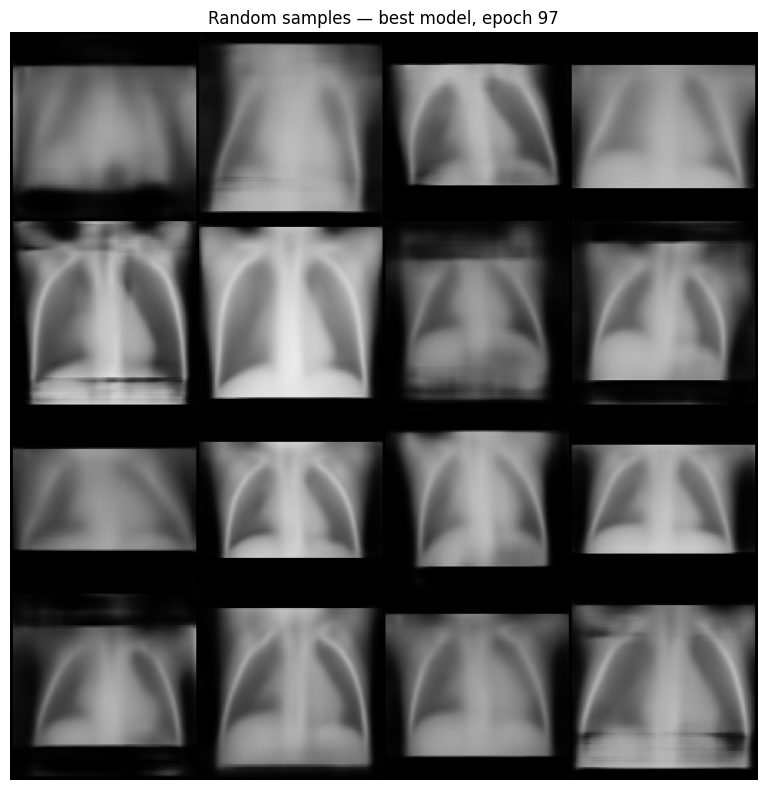

In [ ]:
import json
import torch
import matplotlib.pyplot as plt
from torchvision.utils import make_grid, save_image

saved_history = json.loads(
    (RUN_DIR / "history.json").read_text(encoding="utf-8")
)
print("最新保存的轮次:", saved_history[-1]["epoch"])

checkpoint = torch.load(
    RUN_DIR / "best.pt",
    map_location="cpu",
    weights_only=True,
)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print("最佳模型轮次:", checkpoint["epoch"])
print("最佳验证损失:", checkpoint["best_val_loss"])
z = torch.load(
    RUN_DIR / "fixed_z.pt",
    map_location="cpu",
    weights_only=True,
).to(device)

with torch.no_grad():
    generated = model.decode(z).cpu()

save_image(
    generated,
    RUN_DIR / "best_generated.png",
    nrow=4,
    normalize=False,
)

grid = make_grid(generated, nrow=4, padding=2)
plt.figure(figsize=(8, 8))
plt.imshow(grid.permute(1, 2, 0).numpy(), vmin=0, vmax=1)
plt.axis("off")
plt.title(f"Random samples — best model, epoch {checkpoint['epoch']}")
plt.tight_layout()
plt.show()

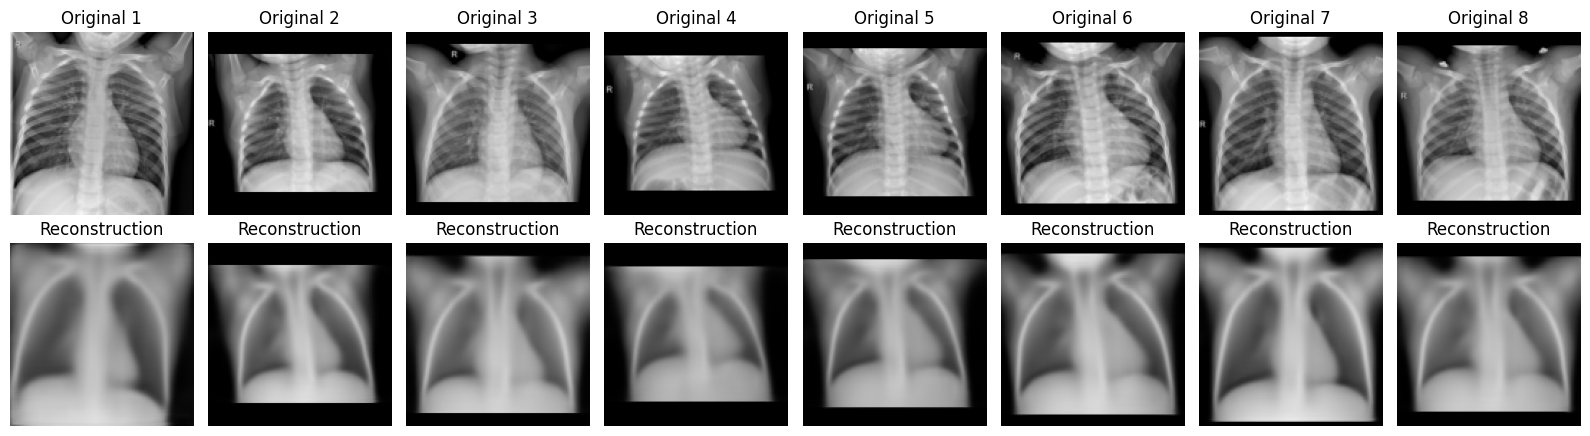

In [ ]:
import matplotlib.pyplot as plt

model.eval()
images = next(iter(val_loader))[:8].to(device)

with torch.no_grad():
    mu, _ = model.encode(images)
    reconstructions = model.decode(mu)

originals = images.cpu()
reconstructions = reconstructions.cpu()
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))

for i in range(8):
    axes[0, i].imshow(
        originals[i, 0], cmap="gray", vmin=0, vmax=1
    )
    axes[1, i].imshow(
        reconstructions[i, 0], cmap="gray", vmin=0, vmax=1
    )
    axes[0, i].set_title(f"Original {i + 1}")
    axes[1, i].set_title("Reconstruction")
    axes[0, i].axis("off")
    axes[1, i].axis("off")

plt.tight_layout()
fig.savefig(
    RUN_DIR / "validation_reconstructions.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

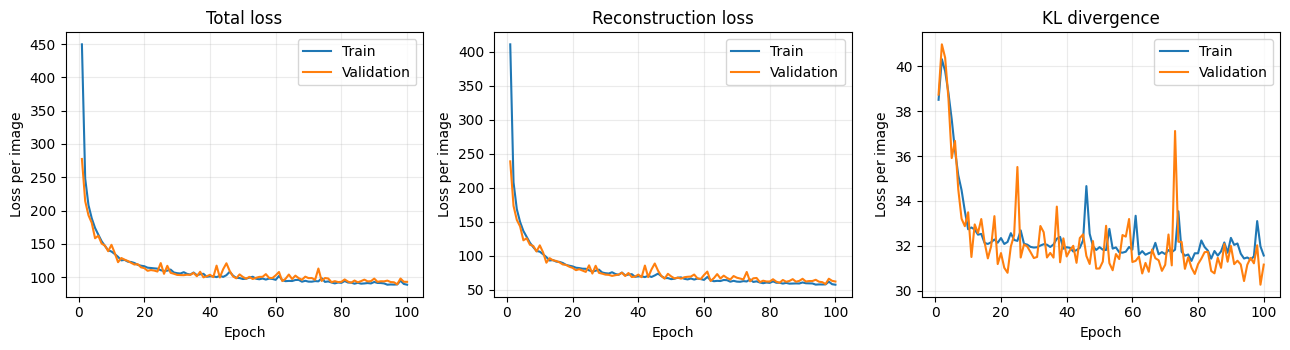

In [15]:
import json
import matplotlib.pyplot as plt

history = json.loads(
    (RUN_DIR / "history.json").read_text(encoding="utf-8")
)
epochs = [row["epoch"] for row in history]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

for ax, key, title in zip(
    axes,
    ("loss", "reconstruction", "kl"),
    ("Total loss", "Reconstruction loss", "KL divergence"),
):
    ax.plot(
        epochs, [row["train"][key] for row in history],
        label="Train"
    )
    ax.plot(
        epochs, [row["val"][key] for row in history],
        label="Validation"
    )
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss per image")
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
fig.savefig(RUN_DIR / "loss_curves.png", dpi=200)
fig.savefig(RUN_DIR / "loss_curves.pdf")
plt.show()

In [16]:
%pip install -q --no-deps pytorch-ignite==0.5.5

import torch
import torchvision
import ignite
import scipy
from ignite.metrics import FID, InceptionScore

print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("Ignite:", ignite.__version__)
print("SciPy:", scipy.__version__)
print("IS / FID 指标导入成功")

PyTorch: 2.11.0+cu130
torchvision: 0.26.0+cu130
Ignite: 0.5.5
SciPy: 1.16.3
IS / FID 指标导入成功


In [ ]:
import torch
import torch.nn.functional as F
from torchvision.models import inception_v3, Inception_V3_Weights
from ignite.metrics import FID, InceptionScore

inception = inception_v3(
    weights=Inception_V3_Weights.IMAGENET1K_V1
).to(device).eval()

inception_classifier = inception.fc
inception.fc = torch.nn.Identity()
inception.requires_grad_(False)
inception_classifier.requires_grad_(False)

mean = torch.tensor(
    [0.485, 0.456, 0.406], device=device
).view(1, 3, 1, 1)
std = torch.tensor(
    [0.229, 0.224, 0.225], device=device
).view(1, 3, 1, 1)

@torch.no_grad()
def extract_inception_outputs(images):
    images = images.to(device)
    images = images.repeat(1, 3, 1, 1)  
    images = F.interpolate(
        images,
        size=(299, 299),
        mode="bilinear",
        align_corners=False,
        antialias=True,
    )
    images = (images - mean) / std

    features = inception(images)
    probabilities = inception_classifier(features).softmax(dim=1)
    return features.cpu(), probabilities.cpu()

fid_metric = FID(num_features=2048, device="cpu")
is_metric = InceptionScore(num_features=1000, device="cpu")

probe = next(iter(val_loader))[:2]
features, probabilities = extract_inception_outputs(probe)

assert features.shape == (2, 2048)
assert probabilities.shape == (2, 1000)
assert torch.isfinite(features).all()
assert torch.allclose(
    probabilities.sum(dim=1), torch.ones(2), atol=1e-5
)

print("FID 特征尺寸:", tuple(features.shape))
print("IS 概率尺寸:", tuple(probabilities.shape))
print("评价网络检查通过，尚未计算最终指标")

Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 215MB/s]


FID 特征尺寸: (2, 2048)
IS 概率尺寸: (2, 1000)
评价网络检查通过，尚未计算最终指标


In [ ]:
import json
import torch

checkpoint = torch.load(
    RUN_DIR / "best.pt",
    map_location="cpu",
    weights_only=True,
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

fid_metric.reset()
is_metric.reset()

eval_generator = torch.Generator().manual_seed(2027)
evaluated = 0

with torch.no_grad():
    for real_images in test_loader:
        n = real_images.size(0)

        z = torch.randn(
            n,
            model.latent_dim,
            generator=eval_generator,
        ).to(device)
        fake_images = model.decode(z)

        real_features, _ = extract_inception_outputs(real_images)
        fake_features, fake_probabilities = extract_inception_outputs(
            fake_images
        )

        fid_metric.update((fake_features, real_features))
        is_metric.update(fake_probabilities)

        evaluated += n
        print(
            f"\r已处理 {evaluated}/{len(test_dataset)} 对样本",
            end="",
            flush=True,
        )

print("\n正在计算最终指标，FID 的矩阵运算可能需要一些时间……",
      flush=True)

fid_value = float(fid_metric.compute())
is_value = float(is_metric.compute())

results = {
    "checkpoint_epoch": checkpoint["epoch"],
    "real_images": evaluated,
    "generated_images": evaluated,
    "generation_seed": 2027,
    "FID": fid_value,
    "IS": is_value,
    "feature_extractor": "torchvision InceptionV3 IMAGENET1K_V1",
    "fid_features": "2048-dimensional average-pooling features",
    "preprocessing": (
        "128x128 grayscale [0,1]; repeat to RGB; "
        "bilinear resize to 299x299 with antialias; "
        "ImageNet mean/std normalization"
    ),
    "ignite_version": str(ignite.__version__),
    "torchvision_version": str(torchvision.__version__),
}

(RUN_DIR / "evaluation.json").write_text(
    json.dumps(results, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print(f"FID: {fid_value:.4f}")
print(f"IS:  {is_value:.4f}")
print("结果已保存:", RUN_DIR / "evaluation.json")

已处理 624/624 对样本
正在计算最终指标，FID 的矩阵运算可能需要一些时间……
FID: 399.8233
IS:  2.1353
结果已保存: /content/drive/MyDrive/ECE285_HW1/vae_20261025_192111_UTC/evaluation.json


In [ ]:
import random
import json
from torch.utils.data import DataLoader
from ignite.metrics import FID

rng = random.Random(2028)
reference_records = []

for label in ("NORMAL", "PNEUMONIA"):
    count = sum(r["label"] == label for r in manifest["test"])
    candidates = [
        r for r in manifest["train"] if r["label"] == label
    ]
    reference_records.extend(rng.sample(candidates, count))

reference_loader = DataLoader(
    ChestXrayDataset(reference_records),
    batch_size=32,
    shuffle=False,
    num_workers=2,
)

reference_fid = FID(num_features=2048, device="cpu")
reference_fid.reset()
processed = 0

for train_images, test_images in zip(reference_loader, test_loader):
    train_features, _ = extract_inception_outputs(train_images)
    test_features, _ = extract_inception_outputs(test_images)

    reference_fid.update((train_features, test_features))
    processed += train_images.size(0)
    print(f"\r已处理 {processed}/624", end="", flush=True)

assert processed == 624
print("\n正在计算真实图参照 FID……", flush=True)
reference_value = float(reference_fid.compute())

audit = {
    "real_train_vs_real_test_FID": reference_value,
    "images_per_set": processed,
    "sampling_seed": 2028,
    "class_counts_per_set": {"NORMAL": 234, "PNEUMONIA": 390},
    "sampled_train_paths": [r["path"] for r in reference_records],
}

(RUN_DIR / "fid_reference_check.json").write_text(
    json.dumps(audit, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print(f"真实训练图 vs 真实测试图 FID: {reference_value:.4f}")
print("此前随机生成图 vs 真实测试图 FID: 399.8233")

已处理 624/624
正在计算真实图参照 FID……
真实训练图 vs 真实测试图 FID: 29.7785
此前随机生成图 vs 真实测试图 FID: 399.8233


In [ ]:
import json
import torch
from ignite.metrics import FID

checkpoint = torch.load(
    RUN_DIR / "best.pt",
    map_location="cpu",
    weights_only=True,
)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device).eval()

reconstruction_fid = FID(num_features=2048, device="cpu")
reconstruction_fid.reset()
processed = 0

with torch.no_grad():
    for real_images in test_loader:
        real_images = real_images.to(device)
        mu, _ = model.encode(real_images)
        reconstructed_images = model.decode(mu)

        real_features, _ = extract_inception_outputs(real_images)
        reconstructed_features, _ = extract_inception_outputs(
            reconstructed_images
        )

        reconstruction_fid.update(
            (reconstructed_features, real_features)
        )
        processed += real_images.size(0)
        print(
            f"\r已处理 {processed}/{len(test_dataset)} 张",
            end="",
            flush=True,
        )

assert processed == len(test_dataset)
print("\n正在计算重建 FID……", flush=True)
reconstruction_value = float(reconstruction_fid.compute())

reconstruction_results = {
    "checkpoint_epoch": checkpoint["epoch"],
    "images_per_set": processed,
    "reconstruction_method": "z = posterior mean mu(x)",
    "reconstruction_FID": reconstruction_value,
    "feature_extractor": "torchvision InceptionV3 IMAGENET1K_V1",
    "feature_dimension": 2048,
    "preprocessing": "same extract_inception_outputs as generation evaluation",
}

result_path = RUN_DIR / "reconstruction_evaluation.json"
result_path.write_text(
    json.dumps(reconstruction_results, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print(f"测试图重建 vs 真实测试图 FID: {reconstruction_value:.4f}")
print("结果已保存:", result_path)

已处理 624/624 张
正在计算重建 FID……
测试图重建 vs 真实测试图 FID: 346.8250
结果已保存: /content/drive/MyDrive/ECE285_HW1/vae_20261025_192111_UTC/reconstruction_evaluation.json
